
# Localized Neutrinos in Two Dark Dimensions — All Manuscript Figures

This notebook reproduces the **five manuscript figures** from the current 2DD localized-neutrino draft and saves both PDF and high-resolution PNG files.




## Core relations used throughout

For two equal compact dimensions,

$$
\overline M_{\rm Pl}^{\,2}=M_6^4(2\pi R)^2,
$$

so

$$
R=\frac{\overline M_{\rm Pl}}{2\pi M_6^2},
\qquad
R^{-1}=\frac{2\pi M_6^2}{\overline M_{\rm Pl}}.
$$

For a flat sterile zero mode,

$$
m_D^{\rm flat}
=
\frac{y_6v}{\sqrt{2}}\frac{M_6}{\overline M_{\rm Pl}}.
$$

For the localized Gaussian zero mode,

$$
m_D^{\rm loc}
=
\frac{y_6v}{\sqrt{\pi}M_6}\,\mu.
$$

The brane-visible localized shells satisfy

$$
M_s^2=8\mu^2s,
\qquad
\theta_{is}^2
\simeq
\frac{m_i^2}{8\mu^2s},
$$

where we use $m_{D,i}\simeq m_i$ at leading order in the perturbative regime.


In [1]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------
OUTDIR = Path("figures")
OUTDIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Plot style: large/bold labels and clear major/minor ticks
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (8.6, 6.4),
    "figure.dpi": 130,
    "savefig.dpi": 500,
    "font.size": 15,
    "axes.labelsize": 20,
    "axes.labelweight": "bold",
    "axes.linewidth": 1.4,
    "legend.fontsize": 13,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "lines.linewidth": 2.3,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def style_axis(ax, logx=False, logy=False):
    if logx:
        ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")
    ax.minorticks_on()
    ax.tick_params(axis="both", which="major", length=7, width=1.4)
    ax.tick_params(axis="both", which="minor", length=4, width=1.1)
    for lab in ax.get_xticklabels() + ax.get_yticklabels():
        lab.set_fontweight("bold")
    ax.grid(True, which="major", alpha=0.22)
    ax.grid(True, which="minor", alpha=0.10)
    return ax

def save_figure(fig, stem):
    fig.savefig(OUTDIR / f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(OUTDIR / f"{stem}.png", bbox_inches="tight", dpi=500)
    print(f"saved: {OUTDIR / (stem + '.pdf')}")
    print(f"saved: {OUTDIR / (stem + '.png')}")



## Numerical inputs

We use the benchmark values appearing in the manuscript:

$$
\overline M_{\rm Pl}=2.435\times10^{18}\ {\rm GeV},
\qquad
M_6=10\ {\rm TeV},
\qquad
m_{\rm lightest}=0.01\ {\rm eV}.
$$

For the representative oscillation inputs,

$$
\sin^2\theta_{12}=0.307,
\qquad
\sin^2\theta_{13}=0.02195,
$$

$$
\Delta m_{21}^2=7.49\times10^{-5}\ {\rm eV}^2,
\qquad
\Delta m_{31}^2=2.534\times10^{-3}\ {\rm eV}^2,
$$

and for inverted ordering,

$$
|\Delta m_{32}^2|=2.510\times10^{-3}\ {\rm eV}^2.
$$


In [2]:

# Fundamental inputs
MPL_GEV = 2.435e18
M6_TEV = 10.0
M6_GEV = M6_TEV * 1e3
V_GEV = 246.0
GEVINV_TO_UM = 1.973269804e-10  # 1 GeV^{-1} in micrometres

# Oscillation inputs
SIN2_TH12 = 0.307
SIN2_TH13 = 0.02195
DM21 = 7.49e-5
DM31 = 2.534e-3
DM32_IO = 2.510e-3
M_LIGHTEST = 0.01

# Electron-row PMNS weights |U_ei|^2
C13SQ = 1.0 - SIN2_TH13
UE2 = np.array([
    (1.0 - SIN2_TH12) * C13SQ,
    SIN2_TH12 * C13SQ,
    SIN2_TH13
])

def neutrino_masses(ordering="NO", mlightest=M_LIGHTEST):
    ordering = ordering.upper()
    if ordering == "NO":
        m1 = mlightest
        m2 = np.sqrt(m1**2 + DM21)
        m3 = np.sqrt(m1**2 + DM31)
        return np.array([m1, m2, m3])
    elif ordering == "IO":
        m3 = mlightest
        m2 = np.sqrt(m3**2 + DM32_IO)
        m1 = np.sqrt(m2**2 - DM21)
        return np.array([m1, m2, m3])
    else:
        raise ValueError("ordering must be 'NO' or 'IO'")

MASS_NO = neutrino_masses("NO")
MASS_IO = neutrino_masses("IO")

def m_beta(masses):
    return np.sqrt(np.sum(UE2 * masses**2))

MBETA_NO = m_beta(MASS_NO)
MBETA_IO = m_beta(MASS_IO)

print("NO masses [eV] =", MASS_NO)
print("IO masses [eV] =", MASS_IO)
print("m_beta(NO) [eV] =", MBETA_NO)
print("m_beta(IO) [eV] =", MBETA_IO)
print("sum |U_ei|^2 =", UE2.sum())


NO masses [eV] = [0.01       0.01322498 0.05132251]
IO masses [eV] = [0.05034978 0.05108816 0.01      ]
m_beta(NO) [eV] = 0.013345818637873062
m_beta(IO) [eV] = 0.05004137418291987
sum |U_ei|^2 = 1.0



# Figure 1 — Dirac mass versus six-dimensional Yukawa coupling

For the flat zero mode,

$$
m_D^{\rm flat}
=
\frac{y_6v}{\sqrt{2}}\frac{M_6}{\overline M_{\rm Pl}}.
$$

At $M_6=10\ {\rm TeV}$,

$$
m_D^{\rm flat}
\simeq
7.14\times10^{-4}\,y_6\ {\rm eV}.
$$

For the localized zero mode,

$$
m_D^{\rm loc}
=
\frac{y_6v\mu}{\sqrt{\pi}M_6},
$$

or numerically,

$$
m_D^{\rm loc}
\simeq
1.388\times10^{-2}\,
y_6
\left(\frac{\mu}{\rm eV}\right)
{\rm eV}.
$$


saved: figures\fig02_dirac_mass_yukawa.pdf
saved: figures\fig02_dirac_mass_yukawa.png


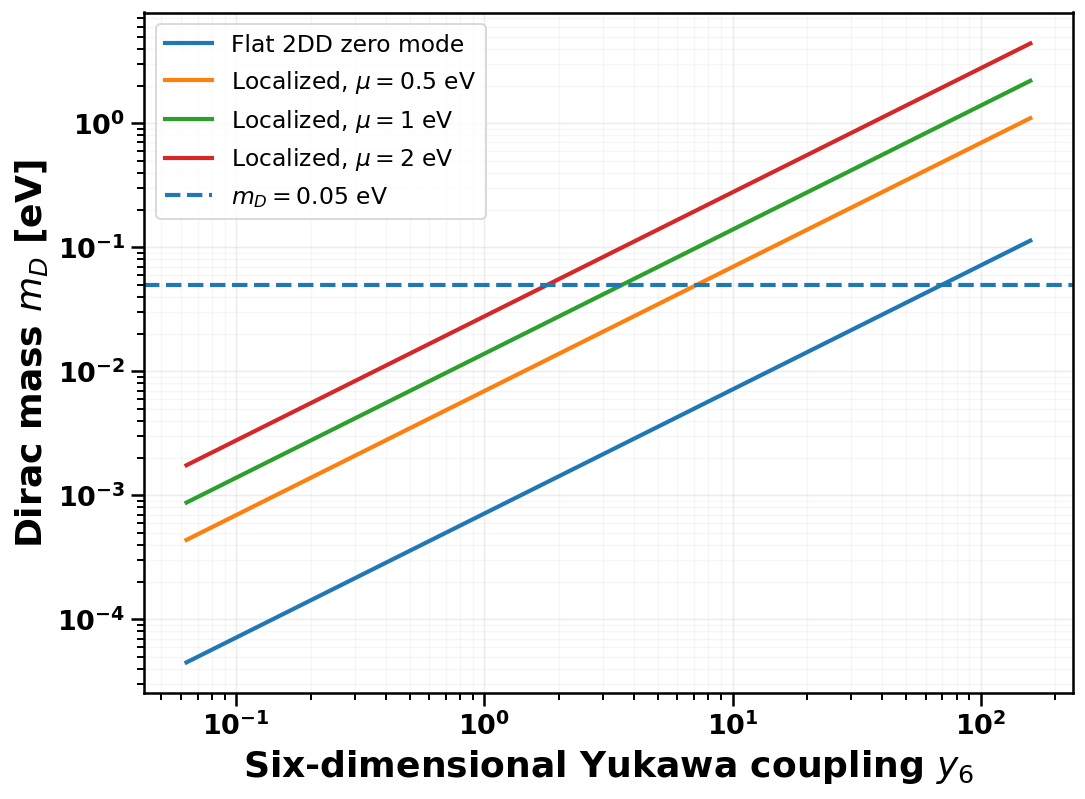

In [3]:

y6 = np.logspace(-1.2, 2.2, 700)

mD_flat = (
    y6 * V_GEV / np.sqrt(2.0)
    * (M6_GEV / MPL_GEV)
    * 1e9
)

def mD_localized(y6, mu_eV, M6_GeV=M6_GEV):
    return y6 * V_GEV / (np.sqrt(np.pi) * M6_GeV) * mu_eV

fig, ax = plt.subplots(figsize=(8.6, 6.4))

ax.plot(y6, mD_flat, label="Flat 2DD zero mode")

for mu in [0.5, 1.0, 2.0]:
    ax.plot(y6, mD_localized(y6, mu), label=fr"Localized, $\mu={mu:g}$ eV")

ax.axhline(0.05, linestyle="--", label=r"$m_D=0.05$ eV")

style_axis(ax, logx=True, logy=True)
ax.set_xlabel(r"Six-dimensional Yukawa coupling $y_6$")
ax.set_ylabel(r"Dirac mass $m_D$ [eV]")
ax.legend(frameon=True, loc="upper left")
fig.tight_layout()

save_figure(fig, "fig02_dirac_mass_yukawa")
plt.show()



# Figure 2 — Equal-radius 2DD gravity relation and reactor bounds

The compactification radius is

$$
R=\frac{\overline M_{\rm Pl}}{2\pi M_6^2}.
$$

Using

$$
1\ {\rm GeV}^{-1}=1.973269804\times10^{-10}\ \mu{\rm m},
$$

the benchmark $M_6=10\ {\rm TeV}$ gives

$$
R\simeq0.765\ \mu{\rm m}.
$$

The horizontal lines are **comparison scales** from flat-LED analyses; they are not direct exclusions of the localized model.


saved: figures\fig06_radius_reactor_bounds.pdf
saved: figures\fig06_radius_reactor_bounds.png


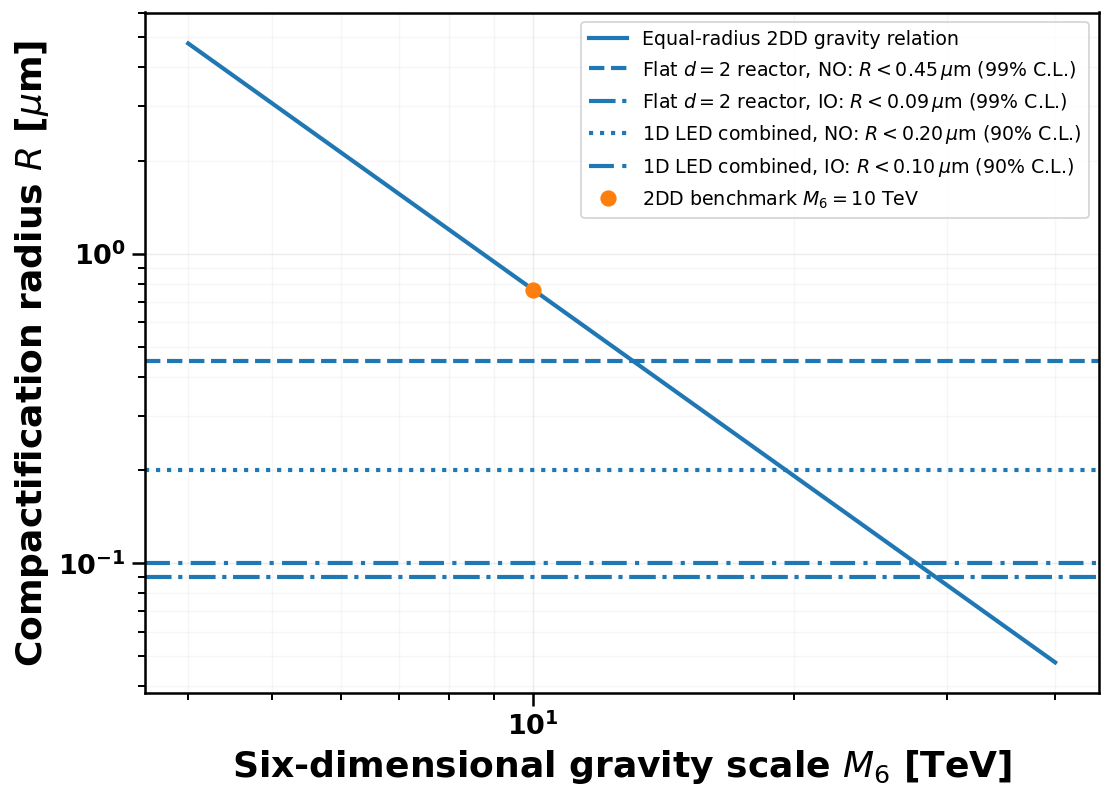

R(M6=10 TeV) = 0.764725 micrometres


In [4]:

M6_scan_TeV = np.logspace(np.log10(4.0), np.log10(40.0), 700)
M6_scan_GeV = M6_scan_TeV * 1e3

R_GeV_inv = MPL_GEV / (2.0 * np.pi * M6_scan_GeV**2)
R_um = R_GeV_inv * GEVINV_TO_UM

R10_um = (
    MPL_GEV / (2.0 * np.pi * M6_GEV**2)
    * GEVINV_TO_UM
)

fig, ax = plt.subplots(figsize=(8.8, 6.4))

ax.plot(M6_scan_TeV, R_um, label="Equal-radius 2DD gravity relation")

ax.axhline(0.45, linestyle="--",
           label=r"Flat $d=2$ reactor, NO: $R<0.45\,\mu$m (99% C.L.)")
ax.axhline(0.09, linestyle="-.",
           label=r"Flat $d=2$ reactor, IO: $R<0.09\,\mu$m (99% C.L.)")
ax.axhline(0.20, linestyle=":",
           label=r"1D LED combined, NO: $R<0.20\,\mu$m (90% C.L.)")
ax.axhline(0.10, linestyle=(0, (6, 2, 1, 2)),
           label=r"1D LED combined, IO: $R<0.10\,\mu$m (90% C.L.)")

ax.plot([10.0], [R10_um], marker="o", markersize=8,
        linestyle="none", label=r"2DD benchmark $M_6=10$ TeV")

style_axis(ax, logx=True, logy=True)
ax.set_xlabel(r"Six-dimensional gravity scale $M_6$ [TeV]")
ax.set_ylabel(r"Compactification radius $R$ [$\mu$m]")
ax.legend(frameon=True, loc="upper right", fontsize=10.5)
fig.tight_layout()

save_figure(fig, "fig06_radius_reactor_bounds")
plt.show()

print(f"R(M6=10 TeV) = {R10_um:.6f} micrometres")



# Figure 3 — Localized shell masses and electron-flavour shell mixing

For the brane-visible shells,

$$
M_s=\sqrt{8s}\,\mu,
\qquad
s=1,2,\ldots
$$

The electron-flavour mixing carried by shell $s$ is

$$
\Theta_{e,s}^2
=
\sum_i |U_{ei}|^2\theta_{is}^2
=
\frac{m_\beta^2}{8\mu^2s},
$$

with

$$
m_\beta^2=\sum_i |U_{ei}|^2m_i^2.
$$

For $m_{\rm lightest}=0.01\ {\rm eV}$,

$$
m_\beta^{\rm NO}\simeq0.01335\ {\rm eV},
\qquad
m_\beta^{\rm IO}\simeq0.05004\ {\rm eV}.
$$


saved: figures\fig10_localized_shell_masses.pdf
saved: figures\fig10_localized_shell_masses.png


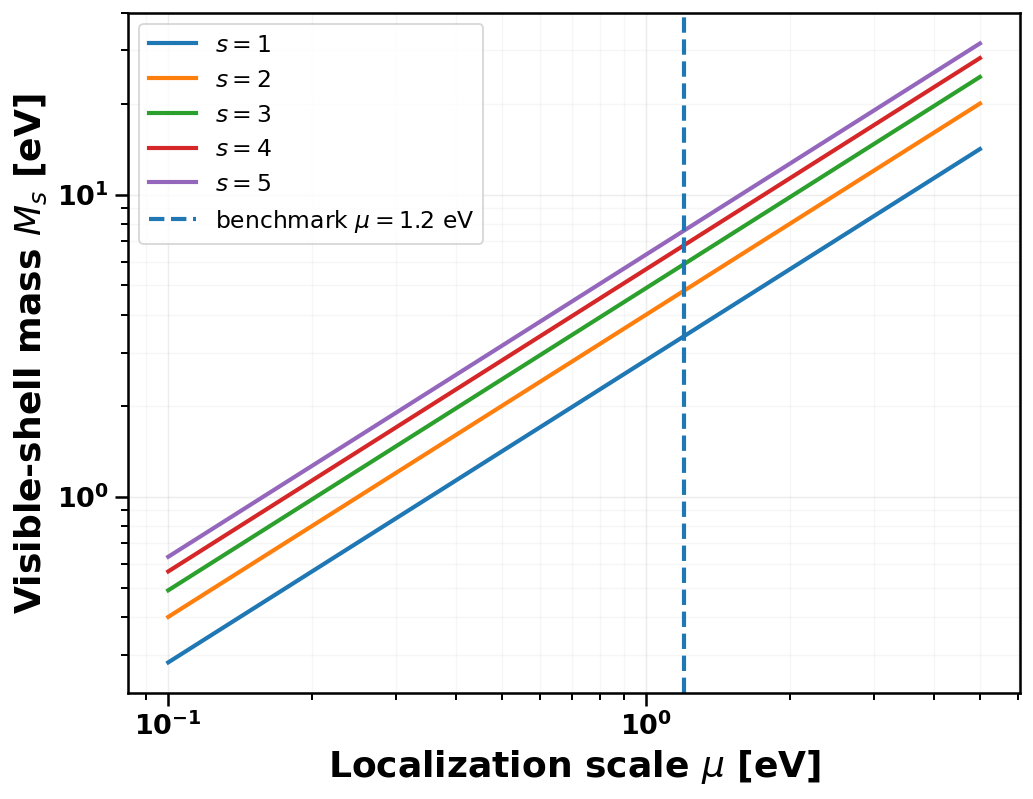

In [5]:

# Figure 3a: visible-shell masses
mu_grid = np.logspace(-1.0, np.log10(5.0), 800)
shells = np.arange(1, 6)

fig, ax = plt.subplots(figsize=(8.2, 6.4))

for s in shells:
    Ms = np.sqrt(8.0 * s) * mu_grid
    ax.plot(mu_grid, Ms, label=fr"$s={s}$")

ax.axvline(1.2, linestyle="--", label=r"benchmark $\mu=1.2$ eV")

style_axis(ax, logx=True, logy=True)
ax.set_xlabel(r"Localization scale $\mu$ [eV]")
ax.set_ylabel(r"Visible-shell mass $M_s$ [eV]")
ax.legend(frameon=True, loc="upper left")
fig.tight_layout()

save_figure(fig, "fig10_localized_shell_masses")
plt.show()


saved: figures\fig10_localized_shell_mixings.pdf
saved: figures\fig10_localized_shell_mixings.png


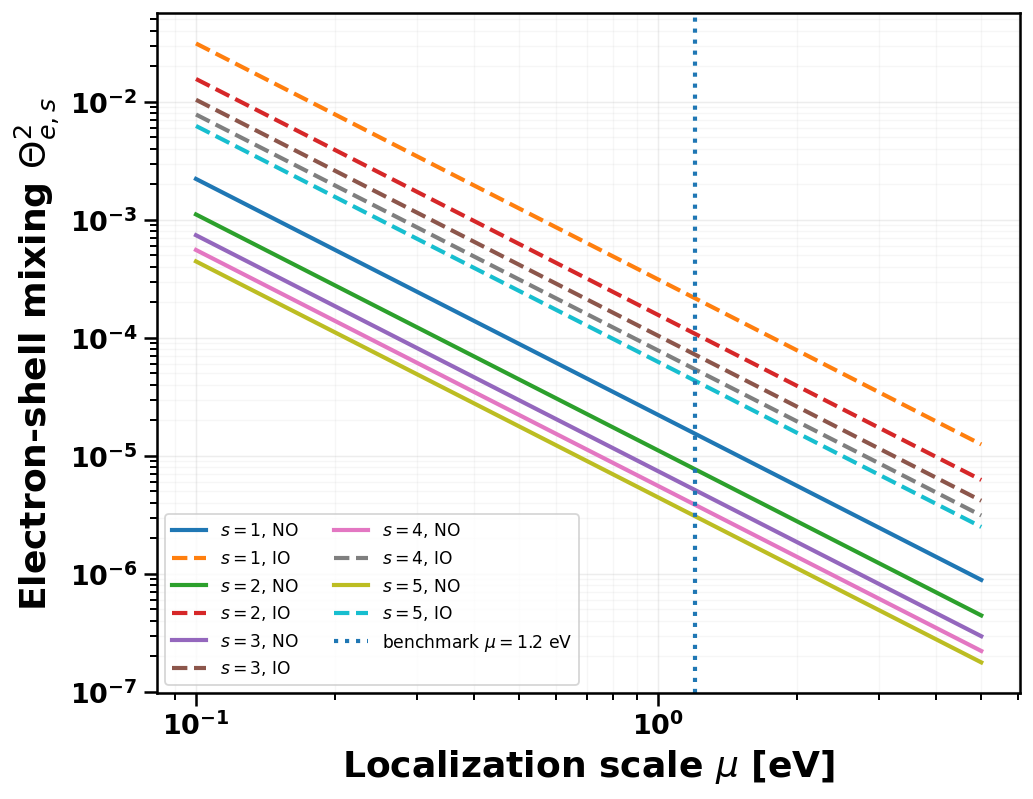

In [6]:

# Figure 3b: electron-shell mixing
fig, ax = plt.subplots(figsize=(8.2, 6.4))

for s in shells:
    mix_no = MBETA_NO**2 / (8.0 * mu_grid**2 * s)
    mix_io = MBETA_IO**2 / (8.0 * mu_grid**2 * s)

    ax.plot(mu_grid, mix_no, linestyle="-", label=fr"$s={s}$, NO")
    ax.plot(mu_grid, mix_io, linestyle="--", label=fr"$s={s}$, IO")

ax.axvline(1.2, linestyle=":", label=r"benchmark $\mu=1.2$ eV")

style_axis(ax, logx=True, logy=True)
ax.set_xlabel(r"Localization scale $\mu$ [eV]")
ax.set_ylabel(r"Electron-shell mixing $\Theta_{e,s}^2$")
ax.legend(frameon=True, fontsize=9.5, ncol=2, loc="lower left")
fig.tight_layout()

save_figure(fig, "fig10_localized_shell_mixings")
plt.show()



### Combined manuscript version of Figure 3

The two panels above are generated as separate high-resolution plots.  
The next cell combines the PNGs **without using matplotlib subplots** and writes the manuscript filename

`figures/fig10_localized_shells.pdf`.


In [7]:

# Combine the two high-resolution panel PNGs side-by-side.
left = Image.open(OUTDIR / "fig10_localized_shell_masses.png").convert("RGB")
right = Image.open(OUTDIR / "fig10_localized_shell_mixings.png").convert("RGB")

target_h = max(left.height, right.height)

def resize_to_height(im, h):
    if im.height == h:
        return im
    new_w = int(round(im.width * h / im.height))
    return im.resize((new_w, h), Image.Resampling.LANCZOS)

left = resize_to_height(left, target_h)
right = resize_to_height(right, target_h)

gap = 50
canvas = Image.new("RGB", (left.width + right.width + gap, target_h), "white")
canvas.paste(left, (0, 0))
canvas.paste(right, (left.width + gap, 0))

png_path = OUTDIR / "fig10_localized_shells.png"
pdf_path = OUTDIR / "fig10_localized_shells.pdf"

canvas.save(png_path, dpi=(500, 500))
canvas.save(pdf_path, "PDF", resolution=500.0)

print("saved:", png_path)
print("saved:", pdf_path)


saved: figures\fig10_localized_shells.png
saved: figures\fig10_localized_shells.pdf



# Figure 4 — Reactor survival probability

For the localized tower,

$$
\mathcal A_{ee}(L,E)
=
\sum_{i=1}^{3}|U_{ei}|^2
\left[
|V_{i0}|^2e^{-im_i^2L/(2E)}
+
\sum_{s\ge1}|V_{is}|^2e^{-iM_{is}^2L/(2E)}
\right].
$$

For sufficiently heavy localized shells the new phases are rapidly averaged.  
The leading coherent contribution is

$$
P_{ee}^{\rm av}
\simeq
\left|
\sum_i |U_{ei}|^2(1-\eta_i)
e^{-im_i^2L/(2E)}
\right|^2,
$$

where

$$
\eta_i
\simeq
\frac{m_i^2}{8\mu^2}
\left[
\ln\left(\frac{\Lambda_{\rm loc}^2}{8\mu^2}\right)+\gamma_E
\right].
$$

For the illustrative curves below we use

$$
\Lambda_{\rm loc}=M_6=10\ {\rm TeV},
$$

as in the manuscript benchmark. This is an **illustrative maximal-cutoff choice**, not a prediction of the low-energy harmonic localizer.


saved: figures\fig07_reactor_probability_shift.pdf
saved: figures\fig07_reactor_probability_shift.png


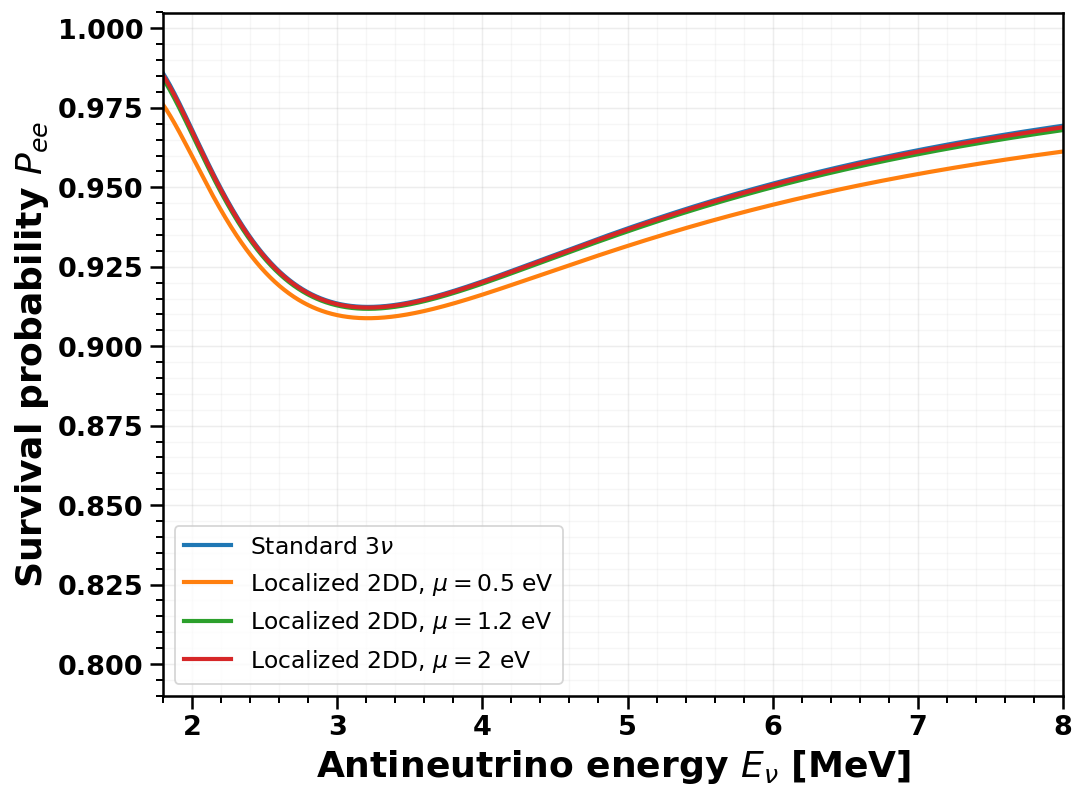

In [8]:

GAMMA_E = 0.5772156649015329
LAMBDA_LOC_EV = M6_TEV * 1e12  # 10 TeV = 1e13 eV
L_KM = 1.6

def eta_i(masses_eV, mu_eV, lambda_loc_eV=LAMBDA_LOC_EV):
    masses_eV = np.asarray(masses_eV, dtype=float)
    return (
        masses_eV**2 / (8.0 * mu_eV**2)
        * (
            np.log(lambda_loc_eV**2 / (8.0 * mu_eV**2))
            + GAMMA_E
        )
    )

def reactor_probability(E_MeV, mu_eV=None, ordering="NO"):
    masses = neutrino_masses(ordering)
    m2 = masses**2
    E_GeV = np.asarray(E_MeV) / 1000.0

    # In the standard convention:
    # probability phase = sin^2(1.267 Δm² L/E)
    # therefore the complex-amplitude phase difference is 2*1.267 Δm² L/E.
    phase = np.exp(
        -1j * 2.0 * 1.267
        * m2[:, None] * L_KM / E_GeV[None, :]
    )

    if mu_eV is None:
        coeff = UE2.copy()
    else:
        coeff = UE2 * (1.0 - eta_i(masses, mu_eV))

    amp = np.sum(coeff[:, None] * phase, axis=0)
    return np.abs(amp)**2

# Dense grid -> smooth numerical rendering
E = np.linspace(1.8, 8.0, 5000)

fig, ax = plt.subplots(figsize=(8.6, 6.4))

ax.plot(E, reactor_probability(E, None, "NO"),
        label=r"Standard $3\nu$")

for mu in [0.5, 1.2, 2.0]:
    ax.plot(E, reactor_probability(E, mu, "NO"),
            label=fr"Localized 2DD, $\mu={mu:g}$ eV")

style_axis(ax)
ax.set_xlim(1.8, 8.0)
ax.set_ylim(0.79, 1.005)
ax.set_xlabel(r"Antineutrino energy $E_\nu$ [MeV]")
ax.set_ylabel(r"Survival probability $P_{ee}$")
ax.legend(frameon=True, loc="lower left")
fig.tight_layout()

save_figure(fig, "fig07_reactor_probability_shift")
plt.show()



# Figure 5 — Smooth beta-endpoint shape

For a collection of neutrino mass eigenstates,

$$
S(q)
=
\sum_a |U_{ea}|^2
q\sqrt{q^2-m_a^2}\,
\Theta(q-m_a),
\qquad
q=E_0-K_e.
$$

For the localized shells,

$$
M_s=\sqrt{8s}\,\mu,
\qquad
\theta_{is}^2
=
\frac{m_i^2}{8\mu^2s}.
$$

The light-state weights are reduced by

$$
|V_{i0}|^2\simeq1-\eta_i.
$$

The plotted quantity is the endpoint-normalized distortion

$$
10^3
\left[
\frac{S_{\rm loc}(q)/S_{3\nu}(q)}
     {S_{\rm loc}(40\,{\rm eV})/S_{3\nu}(40\,{\rm eV})}
-1
\right].
$$

The overall normalization is therefore floated at $q=40\ {\rm eV}$, as in the manuscript.

### Smooth rendering

A very dense $q$ grid is used below, beginning at $q=0.5\,\mathrm{eV}$ so the plot focuses on the eV-scale sterile thresholds rather than the unresolved sub-eV light-neutrino endpoint structure.  
No spline is applied across thresholds, because the changes in curvature at

$$
q=M_s
$$

are physical.


saved: figures\fig08_beta_shape.pdf
saved: figures\fig08_beta_shape.png


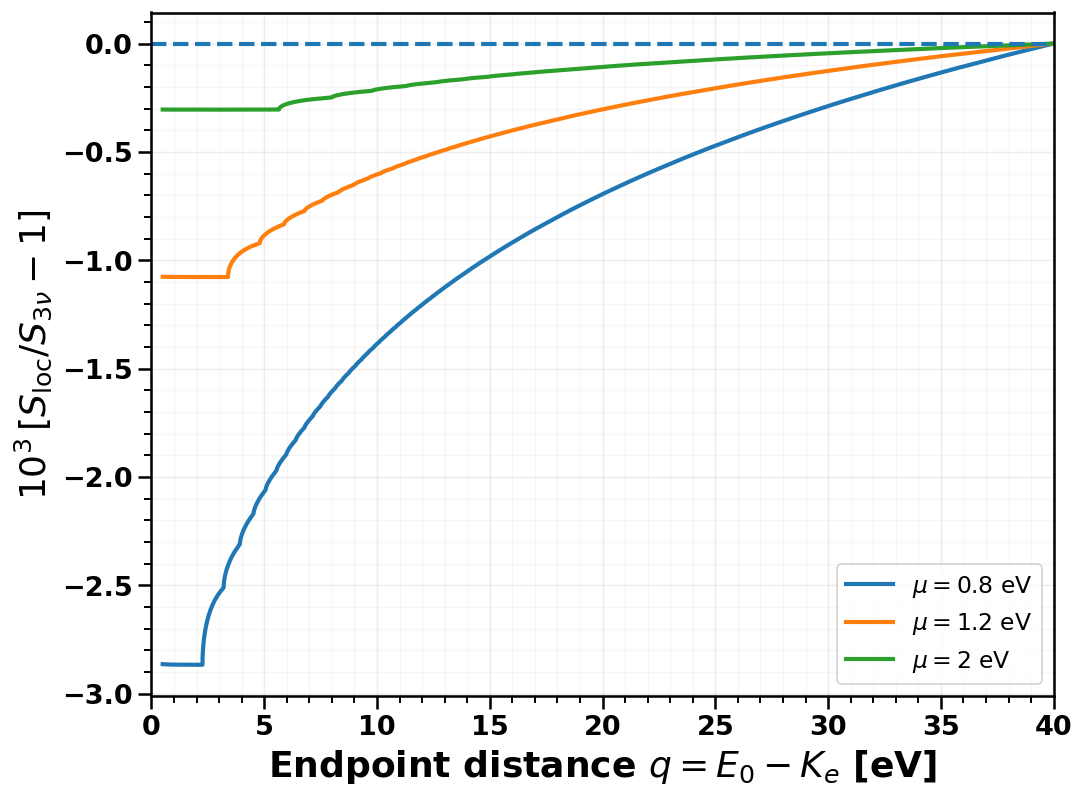

In [12]:

def beta_phase_space(q_eV, mass_eV):
    q = np.asarray(q_eV, dtype=float)
    rad = np.maximum(q**2 - mass_eV**2, 0.0)
    return np.where(q > mass_eV, q * np.sqrt(rad), 0.0)

def beta_standard(q_eV, ordering="IO"):
    masses = neutrino_masses(ordering)
    total = np.zeros_like(np.asarray(q_eV, dtype=float))
    for i in range(3):
        total += UE2[i] * beta_phase_space(q_eV, masses[i])
    return total

def beta_localized(q_eV, mu_eV, ordering="IO",
                   lambda_loc_eV=LAMBDA_LOC_EV):
    q = np.asarray(q_eV, dtype=float)
    masses = neutrino_masses(ordering)
    etas = eta_i(masses, mu_eV, lambda_loc_eV)

    total = np.zeros_like(q)

    # Light states
    for i in range(3):
        total += (
            UE2[i] * (1.0 - etas[i])
            * beta_phase_space(q, masses[i])
        )

    # Only shells kinematically accessible in the plotted window are needed.
    qmax = float(np.max(q))
    smax = int(np.floor(qmax**2 / (8.0 * mu_eV**2)))

    for s in range(1, smax + 1):
        Ms = np.sqrt(8.0 * s) * mu_eV
        shell_ps = beta_phase_space(q, Ms)

        for i in range(3):
            theta2_is = masses[i]**2 / (8.0 * mu_eV**2 * s)
            total += UE2[i] * theta2_is * shell_ps

    return total

# Very dense grid for a smooth numerical curve while retaining physical kinks
# Start at 0.5 eV to stay above the unresolved light-neutrino thresholds
# and focus on the eV-scale localized-shell kinks.
q = np.linspace(0.5, 40.0, 1000000)
S3 = beta_standard(q, ordering="IO")

fig, ax = plt.subplots(figsize=(8.6, 6.4))

for mu in [0.8, 1.2, 2.0]:
    Sloc = beta_localized(q, mu, ordering="IO")
    ratio = Sloc / S3

    # Float the endpoint normalization at q = 40 eV.
    ratio = ratio / ratio[-1]

    distortion = 1e3 * (ratio - 1.0)

    ax.plot(q, distortion, label=fr"$\mu={mu:g}$ eV", antialiased=True)

ax.axhline(0.0, linestyle="--")
style_axis(ax)
ax.set_xlim(0.0, 40.0)
ax.set_xlabel(r"Endpoint distance $q=E_0-K_e$ [eV]")
ax.set_ylabel(r"$10^3\,[S_{\rm loc}/S_{3\nu}-1]$")
ax.legend(frameon=True, loc="lower right")
fig.tight_layout()

# Main manuscript filename
save_figure(fig, "fig08_beta_shape")

# Alias emphasizing that the curve is numerically smooth
fig.savefig(OUTDIR / "fig08_beta_shape_smooth.pdf", bbox_inches="tight")
fig.savefig(OUTDIR / "fig08_beta_shape_smooth.png", bbox_inches="tight", dpi=500)

plt.show()



## Benchmark cross-checks

For the benchmark

$$
M_6=10\ {\rm TeV},
\qquad
\mu=1.2\ {\rm eV},
\qquad
m_{\rm lightest}=0.01\ {\rm eV},
$$

the notebook should reproduce approximately

$$
R=0.765\ \mu{\rm m},
$$

$$
m_\beta^{\rm NO}=0.01335\ {\rm eV},
\qquad
m_\beta^{\rm IO}=0.05004\ {\rm eV},
$$

$$
M_{\rm vis,1}=2\sqrt2\,\mu\simeq3.394\ {\rm eV},
$$

and

$$
\Theta_{e,1}^2
=
\frac{m_\beta^2}{8\mu^2}.
$$


In [10]:

MU_BENCH = 1.2

theta_e1_no = MBETA_NO**2 / (8.0 * MU_BENCH**2)
theta_e1_io = MBETA_IO**2 / (8.0 * MU_BENCH**2)
Mvis1 = np.sqrt(8.0) * MU_BENCH

eta_e_no = np.sum(UE2 * eta_i(MASS_NO, MU_BENCH))
eta_e_io = np.sum(UE2 * eta_i(MASS_IO, MU_BENCH))

print("Benchmark summary")
print("-----------------")
print(f"R [micrometres]         = {R10_um:.6f}")
print(f"m_beta NO [eV]          = {MBETA_NO:.8f}")
print(f"m_beta IO [eV]          = {MBETA_IO:.8f}")
print(f"M_vis,1 [eV]            = {Mvis1:.6f}")
print(f"Theta_e,1^2 NO          = {theta_e1_no:.6e}")
print(f"Theta_e,1^2 IO          = {theta_e1_io:.6e}")
print(f"eta_e NO (Lambda=M6)    = {eta_e_no:.6e}")
print(f"eta_e IO (Lambda=M6)    = {eta_e_io:.6e}")


Benchmark summary
-----------------
R [micrometres]         = 0.764725
m_beta NO [eV]          = 0.01334582
m_beta IO [eV]          = 0.05004137
M_vis,1 [eV]            = 3.394113
Theta_e,1^2 NO          = 1.546101e-05
Theta_e,1^2 IO          = 2.173732e-04
eta_e NO (Lambda=M6)    = 8.967441e-04
eta_e IO (Lambda=M6)    = 1.260772e-02
